### 뇌졸중 예측 - 추가 분석 1편 : 정확도의 함정
### 학습 내용
 * 기본 분석([01_02_Stroke_Prediction_Analysis_01](https://ldjwj.github.io/dataAnalysis/01_02_Stroke_Prediction_Analysis_01.html))의 **테스트 정확도 약 95%**가 정말 좋은 결과인지 확인하기
 * **기준선 모델(DummyClassifier)**과 비교하는 습관 익히기
 * 불균형 데이터에서 쓰는 평가 지표 - **오차행렬, 정밀도/재현율/F1, ROC-AUC, PR 곡선** 이해하기

### 내용
 * 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 1. 데이터 준비 (결측치, 'Other' 성별 처리)
 * 2. 원본 모델 재현 + 기준선(Dummy)과 비교
 * 3. 층화(stratify) 분할로 다시 평가하기
 * 4. 오차행렬 - 95%의 정체
 * 5. 정밀도 / 재현율 / F1
 * 6. ROC 곡선과 PR 곡선
 * 7. 정리

### 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 기본 분석은 `age, hypertension, heart_disease, avg_glucose_level` (+ `id`)로 KNN / 의사결정트리 / 랜덤포레스트를 학습했다.
   * 테스트 정확도 : KNN **94.85%**, 의사결정트리 **95.04%**, 랜덤포레스트 (출력 코드가 `model2`로 되어 있어 실제로는 의사결정트리 결과 **95.04%**가 출력됨)
 * **뇌졸중 환자 비율은 4.87%** (5,110명 중 249명)
   * 모든 사람을 "뇌졸중 없음"으로 예측해도 정확도는 4,861 / 5,110 = **95.1%**
   * 즉, 95%라는 숫자만으로는 모델이 **아무것도 배우지 않았을 가능성**을 배제할 수 없다.
 * 그 밖에 보완할 점
   * `id`는 환자 번호(식별자)일 뿐 뇌졸중과 관계가 없는 값인데 입력 변수에 들어가 있다.
   * `train_test_split`에 `stratify`를 쓰지 않아 학습/테스트의 뇌졸중 비율이 달라질 수 있다.
   * 정확도 외의 지표(재현율 등)를 보지 않았다.

### 필수 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             classification_report)

# 한글 폰트 설정
# - koreanize-matplotlib이 설치되어 있으면 OS와 상관없이 나눔고딕을 사용 (pip install koreanize-matplotlib)
# - 없으면 OS에 맞는 기본 한글 폰트를 사용
try:
    import koreanize_matplotlib
except ImportError:
    import platform
    plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic',
                                   'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])

### 1. 데이터 준비

In [2]:
dat = pd.read_csv("./data/StrokePrediction/healthcare-dataset-stroke-data.csv")
print(dat.shape)

# 타깃 분포 : 개수와 비율
pd.DataFrame({'환자수': dat['stroke'].value_counts(),
              '비율(%)': (dat['stroke'].value_counts(normalize=True) * 100).round(2)})

(5110, 12)


,환자수,비율(%)
stroke,,
0,4861,95.13
1,249,4.87


* 한줄 확인 : 뇌졸중(1)은 249명, **4.87%**. "없음(0)"이 95.13%를 차지하는 **불균형 데이터**

#### 결측치와 'Other' 성별 확인

In [3]:
print(dat.isna().sum()[dat.isna().sum() > 0])
print()
print(dat['gender'].value_counts())

bmi    201
dtype: int64

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


In [4]:
# bmi가 비어 있는 사람과 아닌 사람의 뇌졸중 비율 비교
dat.groupby(dat['bmi'].isna())['stroke'].agg(['size', 'mean']).rename(
    index={False: 'bmi 있음', True: 'bmi 결측'}, columns={'size': '환자수', 'mean': '뇌졸중 비율'})

,환자수,뇌졸중 비율
bmi,,
bmi 있음,4909,0.042575
bmi 결측,201,0.199005


* 한줄 확인 : 결측치는 `bmi`에만 201개(3.9%). 그런데 **bmi 결측 그룹의 뇌졸중 비율은 19.9%**로, bmi가 있는 그룹(4.3%)보다 훨씬 높다.
   * 결측 자체가 정보를 담고 있으므로 결측 행을 그냥 지우면 뇌졸중 환자 40명(201명 × 19.9%)을 잃게 된다.
   * 1편은 원본과 같이 `bmi`를 **사용하지 않으므로** 결측 처리가 필요 없다. 2편에서 bmi를 넣을 때 "중앙값 대체 + 결측 여부 표시" 방법을 사용한다.
 * `gender`의 **'Other'는 단 1명**(뇌졸중 없음). 1명으로는 어떤 패턴도 배울 수 없고, 범주형 인코딩 시 분할에 따라 학습/테스트 어느 한쪽에만 나타나는 문제가 생기므로 **제거**한다.

In [5]:
dat = dat[dat['gender'] != 'Other'].reset_index(drop=True)
dat.shape

(5109, 12)

### 2. 원본 모델 재현 + 기준선(Dummy)과 비교
 * 원본과 **완전히 같은 조건**(변수 5개 + `id`, `random_state=0`, stratify 없음)으로 다시 학습한다.
   * 원본은 'Other' 제거 전 5,110행을 사용했으므로, 재현을 위해 원본 데이터를 다시 불러온다.
 * **DummyClassifier(strategy='most_frequent')** : 입력과 상관없이 항상 가장 많은 클래스("없음")를 예측하는 **기준선 모델**

In [6]:
raw = pd.read_csv("./data/StrokePrediction/healthcare-dataset-stroke-data.csv")
sel_orig = ['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level']

X_tr0, X_te0, y_tr0, y_te0 = train_test_split(raw[sel_orig], raw['stroke'],
                                              test_size=0.3, random_state=0)

orig_models = {
    '기준선(Dummy)': DummyClassifier(strategy='most_frequent'),
    'KNN': KNeighborsClassifier(),
    '의사결정트리': DecisionTreeClassifier(max_depth=3, random_state=0),
    '랜덤포레스트': RandomForestClassifier(max_depth=4, n_estimators=500, random_state=0, n_jobs=2),
}

rows = []
for name, m in orig_models.items():
    m.fit(X_tr0, y_tr0)
    pred = m.predict(X_te0)
    rows.append({'모델': name,
                 '테스트 정확도': accuracy_score(y_te0, pred),
                 '뇌졸중이라고 예측한 수': int(pred.sum()),
                 '맞힌 뇌졸중 환자 수': int(((pred == 1) & (y_te0 == 1)).sum())})

print('테스트 데이터의 실제 뇌졸중 환자 수 :', y_te0.sum(), '/', len(y_te0))
pd.DataFrame(rows).round(4)

테스트 데이터의 실제 뇌졸중 환자 수 : 76 / 1533


,모델,테스트 정확도,뇌졸중이라고 예측한 수,맞힌 뇌졸중 환자 수
0,기준선(Dummy),0.9504,0,0
1,KNN,0.9485,3,0
2,의사결정트리,0.9504,0,0
3,랜덤포레스트,0.9504,0,0


* 한줄 확인 : 원본의 결과(KNN 0.9485, 의사결정트리 0.9504)가 그대로 재현된다.
   * **의사결정트리와 랜덤포레스트의 정확도 0.9504는 기준선(Dummy)과 정확히 같다.**
   * 두 모델은 테스트 데이터에서 뇌졸중을 **단 한 번도 예측하지 않았다** → 사실상 "항상 없음"이라고 답하는 기준선과 같은 모델
   * KNN은 3명을 뇌졸중으로 예측했지만 **실제 환자 76명 중 한 명도 맞히지 못했다.** 정확도는 오히려 기준선보다 낮다.
 * 원본에서 랜덤포레스트를 출력할 때 `model2`(의사결정트리)를 사용했는데, 실제 랜덤포레스트로 계산해도 같은 0.9504가 나온다.

#### `id`는 왜 빼야 할까?
 * `id`는 환자에게 붙인 **일련번호**이다. 번호의 크고 작음은 뇌졸중과 아무 관계가 없다.
 * 이런 변수가 들어가면 트리 모델은 우연히 생긴 패턴(예: 특정 번호 구간)을 외울 수 있고, KNN은 거리 계산이 `id` 값(최대 7만대)에 좌우된다.

In [7]:
# 원본 KNN 입력값의 범위 비교 - 거리 계산에 id가 압도적인 영향을 준다
raw[sel_orig].agg(['min', 'max']).T

,min,max
id,67.00,72940.00
age,0.08,82.00
hypertension,0.00,1.00
heart_disease,0.00,1.00
avg_glucose_level,55.12,271.74


* 한줄 확인 : `id`의 범위(67 ~ 72,940)가 `age`(0.08 ~ 82)나 `hypertension`(0 ~ 1)보다 수백~수만 배 크다. 스케일을 맞추지 않은 KNN은 사실상 **`id`가 비슷한 환자**를 이웃으로 찾고 있었던 셈이다.
 * 이후 분석에서는 **`id`를 제외**하고, KNN에는 `StandardScaler`로 표준화를 적용한다.

### 3. 층화(stratify) 분할로 다시 평가하기
 * `stratify=y` : 학습/테스트 데이터의 뇌졸중 비율을 전체와 같게(약 4.9%) 유지한다.
   * 양성(뇌졸중)이 적을수록 분할에 따라 비율이 흔들리므로 불균형 데이터에서는 거의 필수
 * 변수 : 원본의 4개(`age, hypertension, heart_disease, avg_glucose_level`), `id` 제외

In [8]:
sel = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level']
X = dat[sel]
y = dat['stroke']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=42, stratify=y)

pd.DataFrame({'데이터 수': [len(y_train), len(y_test)],
              '뇌졸중 수': [y_train.sum(), y_test.sum()],
              '뇌졸중 비율(%)': [y_train.mean() * 100, y_test.mean() * 100]},
             index=['학습', '테스트']).round(2)

,데이터 수,뇌졸중 수,뇌졸중 비율(%)
학습,3576,174,4.87
테스트,1533,75,4.89


* 한줄 확인 : 학습/테스트 모두 뇌졸중 비율이 약 4.9%로 같다. 테스트 데이터에는 뇌졸중 환자가 **75명**뿐이다.

In [9]:
models = {
    '기준선(Dummy)': DummyClassifier(strategy='most_frequent'),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    '의사결정트리': DecisionTreeClassifier(max_depth=3, random_state=42),
    '랜덤포레스트': RandomForestClassifier(max_depth=4, n_estimators=500, random_state=42, n_jobs=2),
}

def evaluate(name, model, X_te, y_te):
    """여러 평가 지표를 한 번에 계산"""
    pred = model.predict(X_te)              # 기본 임계값 0.5로 자른 예측(0/1)
    proba = model.predict_proba(X_te)[:, 1]  # 뇌졸중일 확률
    return {'모델': name,
            '정확도': accuracy_score(y_te, pred),
            '정밀도': precision_score(y_te, pred, zero_division=0),
            '재현율': recall_score(y_te, pred),
            'F1': f1_score(y_te, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y_te, proba),
            'PR-AUC(AP)': average_precision_score(y_te, proba),
            '양성 예측 수': int(pred.sum())}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    results.append(evaluate(name, m, X_test, y_test))

res = pd.DataFrame(results).set_index('모델').round(3)
res[['정확도', '양성 예측 수']]

,정확도,양성 예측 수
모델,,
기준선(Dummy),0.951,0
KNN,0.948,6
의사결정트리,0.950,1
랜덤포레스트,0.951,0


* 한줄 확인 : `id`를 빼고 층화 분할을 해도 정확도는 세 모델 모두 0.948 ~ 0.951로 기준선(0.951)을 넘지 못한다.
   * 랜덤포레스트는 뇌졸중 예측이 0건, 의사결정트리는 1건, KNN은 6건뿐이다.

### 4. 오차행렬 - 95%의 정체
 * 오차행렬(Confusion Matrix)은 **실제값 × 예측값**을 4칸으로 나눈 표

| | 예측 : 없음(0) | 예측 : 뇌졸중(1) |
|---|---|---|
| **실제 : 없음(0)** | TN (진짜 음성) | FP (거짓 양성, 오경보) |
| **실제 : 뇌졸중(1)** | FN (거짓 음성, **놓친 환자**) | TP (진짜 양성, 찾아낸 환자) |

 * 정확도 = (TN + TP) / 전체 → TN이 압도적으로 많으면 TP가 0이어도 정확도가 높다.

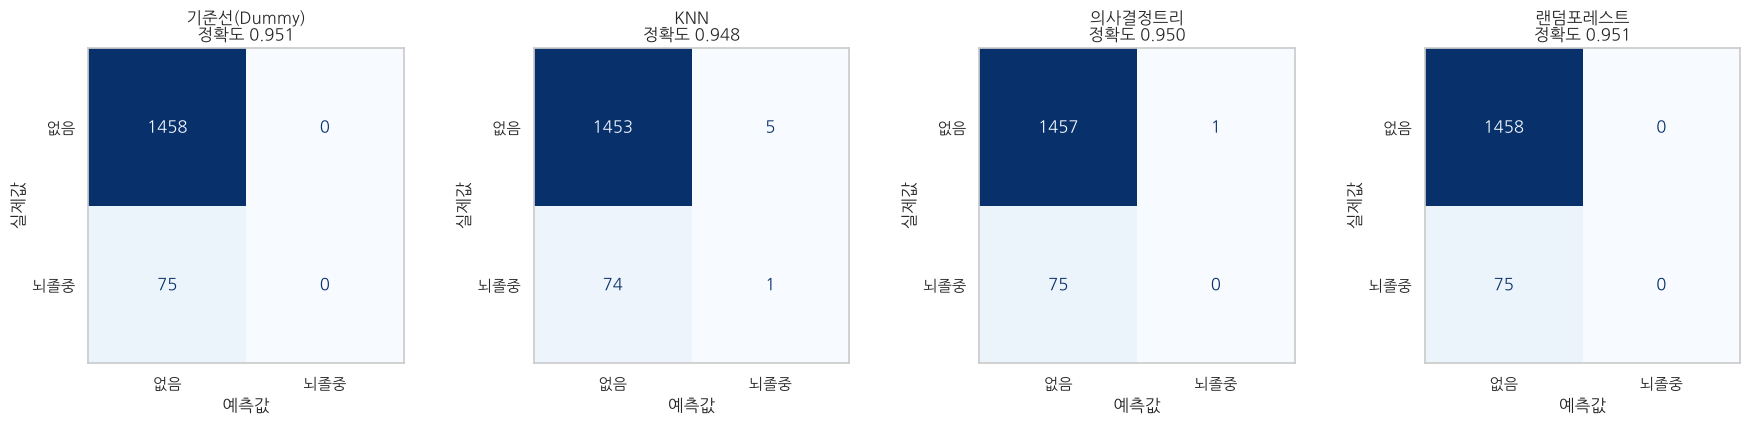

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=['없음', '뇌졸중'], cmap='Blues')
    ax.set_title(f"{name}\n정확도 {res.loc[name, '정확도']:.3f}")
    ax.set_xlabel('예측값')
    ax.set_ylabel('실제값')
    ax.grid(False)
plt.tight_layout()
plt.show()

* 한줄 확인 : 네 모델 모두 오른쪽 아래 칸(TP, 찾아낸 환자)이 0 ~ 1명이다.
   * 실제 뇌졸중 환자 75명 중 KNN은 1명, 의사결정트리·랜덤포레스트·기준선은 **0명**을 찾았다.
   * 95%의 정확도는 "없음"을 맞힌 1,458명(TN)이 만든 숫자이다.

### 5. 정밀도 / 재현율 / F1
 * **재현율(Recall, 민감도)** = TP / (TP + FN) : 실제 환자 중 모델이 찾아낸 비율 → "놓치지 않았나?"
 * **정밀도(Precision)** = TP / (TP + FP) : 모델이 환자라고 한 사람 중 진짜 환자의 비율 → "헛경보가 많지 않나?"
 * **F1** = 정밀도와 재현율의 조화평균 → 둘 중 하나라도 0이면 F1도 0
 * 뇌졸중 같은 질병 예측(선별 검사)에서는 환자를 놓치는 것(FN)이 더 위험하므로 **재현율**을 특히 중요하게 본다.

In [11]:
res[['정확도', '정밀도', '재현율', 'F1', '양성 예측 수']]

,정확도,정밀도,재현율,F1,양성 예측 수
모델,,,,,
기준선(Dummy),0.951,0.000,0.000,0.000,0
KNN,0.948,0.167,0.013,0.025,6
의사결정트리,0.950,0.000,0.000,0.000,1
랜덤포레스트,0.951,0.000,0.000,0.000,0


In [12]:
# 랜덤포레스트의 클래스별 리포트
print(classification_report(y_test, models['랜덤포레스트'].predict(X_test),
                            target_names=['없음(0)', '뇌졸중(1)'], zero_division=0, digits=3))

              precision    recall  f1-score   support

       없음(0)      0.951     1.000     0.975      1458
      뇌졸중(1)      0.000     0.000     0.000        75

    accuracy                          0.951      1533
   macro avg      0.476     0.500     0.487      1533
weighted avg      0.905     0.951     0.927      1533



* 한줄 확인 : 세 모델의 **재현율은 0.000 ~ 0.013**. 정확도 95%인 모델들이 실제 환자를 거의 하나도 찾지 못한다.
   * `classification_report`를 보면 "없음(0)" 클래스는 재현율 1.000으로 완벽하지만, "뇌졸중(1)" 클래스는 정밀도·재현율·F1이 모두 0이다.
   * 마지막 줄의 `macro avg`(두 클래스 단순 평균)와 달리 `weighted avg`(개수 가중 평균)는 다수 클래스에 끌려가 높게 나오는 점도 주의

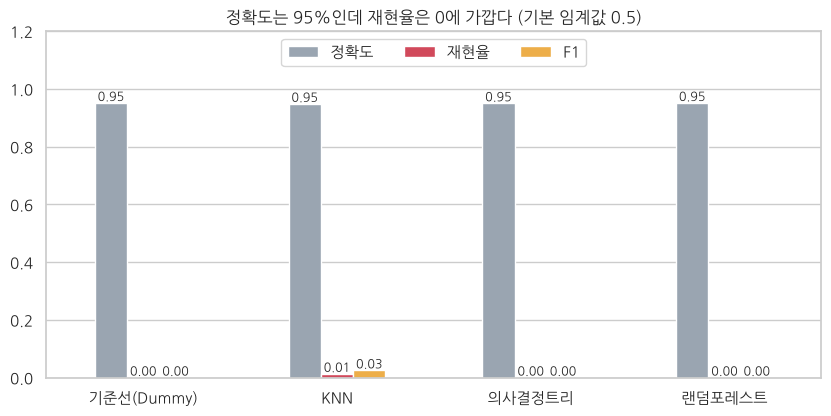

In [13]:
# 정확도 vs 재현율 한눈에 비교
fig, ax = plt.subplots(figsize=(10, 4.5))
res[['정확도', '재현율', 'F1']].plot.bar(ax=ax, rot=0, color=['#9aa5b1', '#d1495b', '#edae49'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=9)
ax.set_ylim(0, 1.2)
ax.grid(axis='x', visible=False)
ax.set_title('정확도는 95%인데 재현율은 0에 가깝다 (기본 임계값 0.5)')
ax.set_xlabel('')
ax.legend(loc='upper center', ncol=3)
plt.show()

### 6. ROC 곡선과 PR 곡선
 * 앞의 지표는 모두 **임계값 0.5**(확률 0.5 이상이면 뇌졸중)로 잘라서 계산한 값이다.
 * 모델이 출력하는 **확률의 순서**가 쓸모 있는지는 임계값과 상관없이 따로 볼 수 있다.
   * **ROC 곡선 / ROC-AUC** : 임계값을 바꿔 가며 (거짓 양성률, 재현율)을 그린 곡선. 0.5 = 무작위, 1.0 = 완벽
   * **PR 곡선 / AP(PR-AUC)** : 임계값을 바꿔 가며 (재현율, 정밀도)를 그린 곡선. 무작위 기준선 = **양성 비율(약 0.049)**
 * 불균형 데이터에서는 ROC-AUC가 다수 클래스(TN) 덕분에 후하게 나오는 경향이 있어 **PR 곡선을 함께** 보는 것이 좋다.

In [14]:
res[['ROC-AUC', 'PR-AUC(AP)']]

,ROC-AUC,PR-AUC(AP)
모델,,
기준선(Dummy),0.500,0.049
KNN,0.691,0.101
의사결정트리,0.828,0.173
랜덤포레스트,0.839,0.219


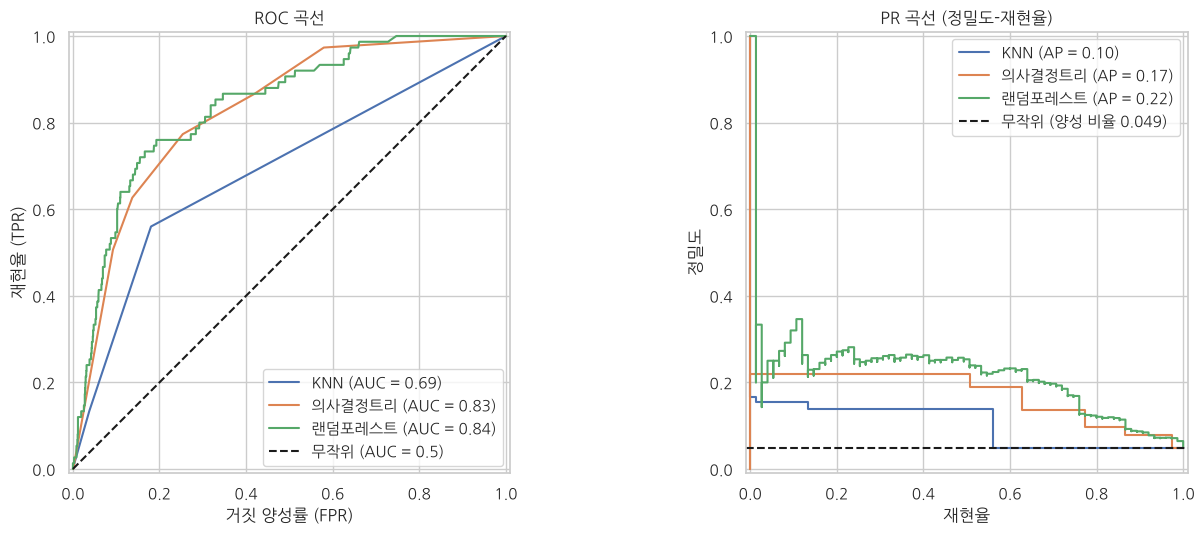

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, m in models.items():
    if name == '기준선(Dummy)':
        continue
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=axes[1], name=name)

axes[0].plot([0, 1], [0, 1], 'k--', label='무작위 (AUC = 0.5)')
axes[0].set_title('ROC 곡선')
axes[0].set_xlabel('거짓 양성률 (FPR)')
axes[0].set_ylabel('재현율 (TPR)')
axes[0].legend(loc='lower right')

axes[1].axhline(y_test.mean(), color='k', ls='--', label=f'무작위 (양성 비율 {y_test.mean():.3f})')
axes[1].set_title('PR 곡선 (정밀도-재현율)')
axes[1].set_xlabel('재현율')
axes[1].set_ylabel('정밀도')
axes[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

* 한줄 확인 : 랜덤포레스트의 **ROC-AUC는 0.839**, 의사결정트리 0.828, KNN 0.691
   * 즉 모델이 낸 확률은 "환자일수록 높게" 어느 정도 **순서를 잘 매기고 있다.** 문제는 0.5라는 임계값이 4.9%짜리 희귀 클래스에 너무 높다는 것
 * PR 곡선의 AP는 랜덤포레스트 0.219로 무작위(0.049)의 약 4.5배이지만, 절대값으로는 낮다.
   * 재현율을 높이려 하면 정밀도가 빠르게 떨어진다 → 환자를 많이 찾으려면 **헛경보를 상당히 감수**해야 한다.

#### 임계값을 낮추면 어떻게 될까? (2편 미리 보기)
 * 랜덤포레스트의 확률을 그대로 두고, 자르는 기준만 0.5 → 더 낮은 값으로 바꿔 본다.
 * 여기서는 개념 확인용으로 테스트 데이터에서 바로 보지만, 실제로는 **학습 데이터(교차검증)로 임계값을 정해야** 한다(2편).

In [16]:
proba_rf = models['랜덤포레스트'].predict_proba(X_test)[:, 1]

rows = []
for th in [0.5, 0.3, 0.2, 0.1, 0.05]:
    pred = (proba_rf >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'임계값': th, '정확도': accuracy_score(y_test, pred),
                 '정밀도': precision_score(y_test, pred, zero_division=0),
                 '재현율': recall_score(y_test, pred),
                 '찾은 환자(TP)': tp, '놓친 환자(FN)': fn, '오경보(FP)': fp})
pd.DataFrame(rows).round(3)

,임계값,정확도,정밀도,재현율,찾은 환자(TP),놓친 환자(FN),오경보(FP)
0,0.50,0.951,0.000,0.000,0,75,0
1,0.30,0.950,0.333,0.013,1,74,2
2,0.20,0.933,0.245,0.173,13,62,40
3,0.10,0.838,0.192,0.720,54,21,227
4,0.05,0.691,0.117,0.813,61,14,459


* 한줄 확인 : 같은 랜덤포레스트라도 임계값을 0.5 → **0.1**로 낮추면 재현율이 0.000 → **0.720**(75명 중 54명 발견)으로 올라간다.
   * 대신 오경보(FP)가 0 → 227건으로 늘고, 정확도는 0.951 → 0.838로 **떨어진다.**
   * 정확도가 낮아졌지만 환자를 찾는 목적에는 훨씬 쓸모 있는 모델이 된다 → **정확도가 높다고 좋은 모델이 아니다.**
 * 정밀도 0.192 : 뇌졸중 위험이라고 알린 281명 중 약 5명에 1명이 실제 환자. 양성 비율(4.9%)의 약 4배이므로 "정밀 검사 대상자 선별"에는 의미가 있다.

### 7. 정리
| 질문 | 기본 분석 | 추가 분석 결과 |
|---|---|---|
| 모델 성능은 좋은가? | 테스트 정확도 약 95% (KNN 94.85%, 트리 95.04%) | 항상 "없음"이라고 답하는 **기준선(Dummy)도 95.04%** (층화 분할 기준 95.1%). 원본 조건에서 트리·랜덤포레스트는 기준선과 **완전히 같은 예측**(뇌졸중 예측 0건) |
| 실제 환자를 찾아내는가? | 확인하지 않음 | 기본 임계값 0.5에서 **재현율 0.000 ~ 0.013** - 테스트 환자 75명 중 최대 1명 발견 |
| 입력 변수는 적절한가? | `id` 포함 | `id`(67 ~ 72,940)는 의미 없는 일련번호. 스케일이 커서 KNN 거리를 지배 → 제외 |
| 학습/테스트 분할은? | stratify 없음 | `stratify=y`로 학습 4.87% / 테스트 4.89% 비율 유지 |
| 모델이 아무것도 못 배운 것인가? | - | 아니다. 랜덤포레스트 **ROC-AUC 0.839**, AP 0.219(무작위 0.049) → 확률의 순서는 쓸모 있고, **임계값 0.5가 문제** |
| 임계값을 낮추면? | - | 0.1에서 재현율 **0.720**(54명 발견), 대신 오경보 227건, 정확도 0.838로 하락 |

#### 배운 점
 * 불균형 데이터에서는 먼저 **기준선(DummyClassifier)** 점수를 계산하고, 모델이 그보다 나은지 확인한다.
 * 정확도 하나로 판단하지 말고 **오차행렬**을 그려 TP / FN(놓친 환자)을 직접 본다.
 * 목적에 맞는 지표를 고른다 - 질병 선별이면 **재현율**, 헛경보 비용이 크면 **정밀도**, 둘의 균형은 **F1**, 임계값과 무관한 순서 능력은 **ROC-AUC / PR-AUC**
 * `predict()`는 임계값 0.5를 쓴다. 희귀 클래스에서는 `predict_proba()`의 확률을 보고 임계값을 정해야 한다.

#### 다음에 해 볼 분석 (2편)
 * 불균형 처리 비교 : `class_weight='balanced'`, 오버샘플링(SMOTE / RandomOverSampler, **학습 데이터에만** 적용), 임계값 조정
 * `bmi`(결측 처리), 흡연, 성별 등 나머지 변수를 넣은 모델과 **위험 요인 EDA**